In [19]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [20]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/student_performance_20000.csv")

In [21]:
df.shape

(20000, 12)

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Age                        20000 non-null  int64  
 1   StudyHoursPerDay           20000 non-null  float64
 2   AttendancePercentage       20000 non-null  float64
 3   PreviousExamScore          20000 non-null  float64
 4   SleepHours                 20000 non-null  float64
 5   AssignmentsCompleted       20000 non-null  int64  
 6   InternetAccess             20000 non-null  object 
 7   ParentEducation            20000 non-null  object 
 8   ExtracurricularActivities  20000 non-null  object 
 9   StudyMethod                20000 non-null  object 
 10  SchoolType                 20000 non-null  object 
 11  ExamScore                  20000 non-null  float64
dtypes: float64(5), int64(2), object(5)
memory usage: 1.8+ MB


In [23]:
df.describe()

,Age,StudyHoursPerDay,AttendancePercentage,PreviousExamScore,SleepHours,AssignmentsCompleted,ExamScore
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,18.499950,3.943715,81.646700,67.954390,7.008130,4.982200,68.163120
std,2.295553,2.552360,11.300997,14.797764,1.201239,3.165309,11.239298
min,15.000000,0.000000,35.900000,11.400000,3.000000,0.000000,28.700000
25%,16.000000,2.000000,73.800000,57.900000,6.200000,2.000000,60.600000
50%,19.000000,3.400000,82.000000,68.000000,7.000000,5.000000,67.900000
75%,21.000000,5.300000,90.100000,78.200000,7.800000,8.000000,75.600000
max,22.000000,12.000000,100.000000,100.000000,11.000000,10.000000,100.000000


In [24]:
df.columns

Index(['Age', 'StudyHoursPerDay', 'AttendancePercentage', 'PreviousExamScore',
       'SleepHours', 'AssignmentsCompleted', 'InternetAccess',
       'ParentEducation', 'ExtracurricularActivities', 'StudyMethod',
       'SchoolType', 'ExamScore'],
      dtype='object')

In [25]:
df.isnull().sum()

Age                          0
StudyHoursPerDay             0
AttendancePercentage         0
PreviousExamScore            0
SleepHours                   0
AssignmentsCompleted         0
InternetAccess               0
ParentEducation              0
ExtracurricularActivities    0
StudyMethod                  0
SchoolType                   0
ExamScore                    0
dtype: int64

In [26]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
19995    False
19996    False
19997    False
19998    False
19999    False
Length: 20000, dtype: bool

In [27]:
X = df.drop("ExamScore", axis=1)
y = df["ExamScore"]

In [28]:
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
print("Numerical Columns:", numerical_cols)
print("Categorical Columns:", categorical_cols)

Numerical Columns: ['Age', 'StudyHoursPerDay', 'AttendancePercentage', 'PreviousExamScore', 'SleepHours', 'AssignmentsCompleted']
Categorical Columns: ['InternetAccess', 'ParentEducation', 'ExtracurricularActivities', 'StudyMethod', 'SchoolType']


In [29]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [30]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [31]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)])

In [34]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        random_state=42
))])

model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Age','StudyHoursPerDay','AttendancePercentage',..., 'ExtracurricularActivities','StudyMethod','SchoolType']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatica

In [36]:
y_pred = model.predict(X_test)
y_pred[:10]

array([81.94591065, 56.5903091 , 71.57756461, 66.04396845, 82.44651695,
       56.55611742, 49.7290888 , 69.53051507, 73.51951384, 81.71898766])

In [37]:
mae = mean_absolute_error(y_test, y_pred)
print("MAE:", mae)

MAE: 5.625839497796203


In [38]:
mse = mean_squared_error(y_test, y_pred)
print("MSE:", mse)

MSE: 49.82723126383802


In [39]:
rmse = np.sqrt(mse)
print("RMSE:", rmse)

RMSE: 7.058840645873657


In [40]:
r2 = r2_score(y_test, y_pred)
print("R2 Score:", r2)

R2 Score: 0.6043477485977009


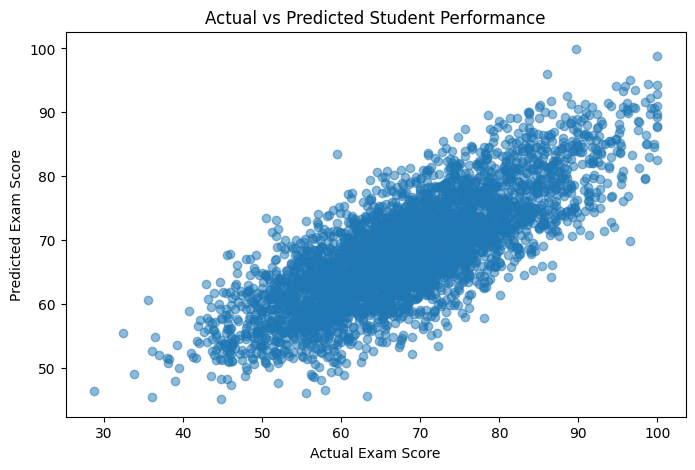

In [41]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Actual vs Predicted Student Performance")
plt.show()

In [42]:
param_dist = {
    "regressor__n_estimators": [50, 100, 150, 200, 300],

    "regressor__learning_rate": [0.01, 0.05, 0.1, 0.15, 0.2],

    "regressor__max_depth": [2, 3, 4, 5],

    "regressor__min_samples_split": [2, 5, 10],

    "regressor__min_samples_leaf": [1, 2, 4],

    "regressor__subsample": [0.7, 0.8, 0.9, 1.0]
}

In [44]:
random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_dist,
    n_iter=15,
    cv=3,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__learning_rate': [0.01, 0.05, ...], 'regressor__max_depth': [2, 3, ...], 'regressor__min_samples_leaf': [1, 2, ...], 'regressor__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, `

In [45]:
print("Best Parameters:")
print(random_search.best_params_)

Best Parameters:
{'regressor__subsample': 0.8, 'regressor__n_estimators': 150, 'regressor__min_samples_split': 2, 'regressor__min_samples_leaf': 1, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.15}


In [46]:
print("Best CV R2 Score:", random_search.best_score_)

Best CV R2 Score: 0.6102826958692585


In [47]:
best_model = random_search.best_estimator_
y_pred_best = best_model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, y_pred_best))
print("MSE:", mean_squared_error(y_test, y_pred_best))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_best)))
print("R2 Score:", r2_score(y_test, y_pred_best))

MAE: 5.605531308240428
MSE: 49.521549689519766
RMSE: 7.037154942838744
R2 Score: 0.606775007749445


In [48]:
best_params = random_search.best_params_

param_grid = {
    "regressor__n_estimators": [
        best_params["regressor__n_estimators"]
    ],

    "regressor__learning_rate": [
        best_params["regressor__learning_rate"]
    ],

    "regressor__max_depth": [
        best_params["regressor__max_depth"]
    ],

    "regressor__min_samples_split": [
        best_params["regressor__min_samples_split"]
    ],

    "regressor__min_samples_leaf": [
        best_params["regressor__min_samples_leaf"]
    ],

    "regressor__subsample": [
        best_params["regressor__subsample"]
    ]
}

In [50]:
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 1 candidates, totalling 3 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__learning_rate': [0.15], 'regressor__max_depth': [2], 'regressor__min_samples_leaf': [1], 'regressor__min_samples_split': [2], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`

In [52]:
print("Best Grid Parameters:", grid_search.best_params_)

print("Best Grid CV Score:", grid_search.best_score_)

Best Grid Parameters: {'regressor__learning_rate': 0.15, 'regressor__max_depth': 2, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 150, 'regressor__subsample': 0.8}
Best Grid CV Score: 0.6102826958692585


In [53]:
best_model = random_search.best_estimator_

y_pred_best = best_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred_best))

print("MSE:", mean_squared_error(y_test, y_pred_best))

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_best)))

print("R2 Score:", r2_score(y_test, y_pred_best))

MAE: 5.605531308240428
MSE: 49.521549689519766
RMSE: 7.037154942838744
R2 Score: 0.606775007749445
